<a href="https://colab.research.google.com/github/DaianaSep/Entrega-final/blob/main/Sepulveda_Daiana_Entrega_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Entrega Final: Notebook Integral de Ciencia de Datos
## Detección de burnout alto en desarrolladores
**Estudiante:** Daiana Sepúlveda  
**Proyecto:** Análisis de desgaste profesional y estrés en desarrolladores

## 1. Definición del problema y carga
En este proyecto retomo el dataset de mis entregas anteriores. El problema consiste en identificar registros con burnout alto a partir de hábitos laborales y personales. Es un problema de **clasificación binaria**: alto (1) frente a bajo o medio (0).

**Pregunta principal:** ¿qué tan bien puedo identificar el burnout alto utilizando información de jornada, descanso y actividad laboral, sin usar directamente el puntaje de estrés?

El objetivo de negocio es orientar la revisión de cargas y las acciones de bienestar de un equipo. El resultado es una señal exploratoria para acompañar decisiones, y requiere validación con datos reales antes de utilizarse.

**Fuente:** archivo `developer_burnout_dataset_7000.csv` conservado en mis [pre-entregas](https://github.com/DaianaSep/pre-entrega-7). No cuento con documentación verificable del método de recolección, las unidades de cafeína ni la construcción de la etiqueta; por eso no asumo representatividad ni una relación causal. Cada fila se trata como un registro independiente, ya que no hay identificador personal ni fecha.

**Ejecución:** Python 3 con pandas, numpy, matplotlib, seaborn y scikit-learn. En Colab están disponibles; en un entorno nuevo se pueden instalar con `%pip install pandas numpy matplotlib seaborn scikit-learn`. Ejecutar todas las celdas en orden. La carga usa el CSV local y, si no existe, lo descarga desde una versión fija de GitHub.

### Ficha técnica y diccionario de datos
El archivo tiene **7.000 registros y 12 columnas**: once variables numéricas y una etiqueta categórica (`burnout_level`). Cada columna contiene 140 faltantes (2 %). El objetivo se construye como `High = 1` y `Low/Medium = 0`; las etiquetas faltantes se excluyen, no se imputan.

El [CSV exacto utilizado](https://raw.githubusercontent.com/DaianaSep/pre-entrega-7/4787bfca25f02f95c04cc1dfd75c63d8257d1093/developer_burnout_dataset_7000.csv) está disponible en una versión fija de mi repositorio. Esta copia permite reproducir el análisis, pero no reemplaza la referencia a la publicación original, cuya URL exacta no pude verificar.

El modelo identifica la etiqueta registrada: no predice un evento futuro, porque no hay fechas ni seguimiento. En una eventual prueba, Bienestar coordinaría conversaciones voluntarias y la persona responsable del equipo revisaría la carga de trabajo con información agregada.

Los aportes de las variables son hipótesis analíticas, no efectos causales demostrados.

| Variable | Tipo y significado | Uso y aporte esperado |
|---|---|---|
| `age` | Numérica; edad en años | Solo filtro de coherencia edad-experiencia; excluida del modelo. |
| `experience_years` | Numérica; años de experiencia | Solo filtro de coherencia con edad; excluida del modelo. |
| `daily_work_hours` | Numérica; horas de trabajo diario | Indicador de duración de jornada y posible sobrecarga. |
| `sleep_hours` | Numérica; horas de sueño | Información de descanso, diferente de la jornada. |
| `caffeine_intake` | Numérica; consumo registrado, unidad no documentada | Indicador exploratorio de hábitos; no se interpreta como dosis. |
| `bugs_per_day` | Numérica; errores por día | Describe incidencias laborales; puede ser antecedente, consecuencia o correlato del desgaste. |
| `commits_per_day` | Numérica; commits por día | Describe actividad de desarrollo; no equivale automáticamente a productividad. |
| `meetings_per_day` | Numérica; reuniones por día | Aproxima carga de coordinación y posibles interrupciones. |
| `screen_time` | Numérica; horas de pantalla registradas | Complementa la jornada, aunque ambas están muy correlacionadas. |
| `exercise_hours` | Numérica; horas de ejercicio registradas | Aporta actividad personal; la periodicidad debe verificarse en la fuente. |
| `stress_level` | Numérica; puntaje de estrés | Solo limpieza y EDA; excluida por posible cercanía con la construcción de la etiqueta. |
| `burnout_level` | Categórica; Low, Medium o High | Objetivo transformado a binario; nunca predictor. |
| `categoria_jornada` | Categórica derivada de horas de trabajo | Tres tramos fijos, codificados con One-Hot dentro del pipeline. |


In [ ]:
from pathlib import Path
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

SEMILLA = 42
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
AZUL, NARANJA = '#246B83', '#D56746'
archivo = Path('developer_burnout_dataset_7000.csv')
url = 'https://raw.githubusercontent.com/DaianaSep/pre-entrega-4/refs/heads/main/developer_burnout_dataset_7000.csv'

df = pd.read_csv(archivo if archivo.exists() else url)
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
print('Dimensiones originales:', df.shape)
display(df.head())
df.info()
display(df.describe().round(2))

Python: 3.9.6 | pandas: 2.3.3 | sklearn: 1.6.1
Dimensiones originales: (7000, 12)


,age,experience_years,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,stress_level,burnout_level
0,26.0,12.0,10.33,4.45,2.0,11.0,4.0,1.0,15.07,0.14,55.96,Medium
1,39.0,10.0,8.62,5.77,5.0,15.0,11.0,5.0,13.25,0.54,82.22,High
2,34.0,13.0,NaN,4.03,5.0,2.0,18.0,9.0,11.18,1.54,61.77,Medium
3,30.0,1.0,6.85,6.47,2.0,15.0,26.0,1.0,11.14,0.96,54.98,Medium
4,27.0,7.0,4.24,5.80,NaN,9.0,17.0,7.0,8.05,0.36,27.90,Low


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               6860 non-null   float64
 1   experience_years  6860 non-null   float64
 2   daily_work_hours  6860 non-null   float64
 3   sleep_hours       6860 non-null   float64
 4   caffeine_intake   6860 non-null   float64
 5   bugs_per_day      6860 non-null   float64
 6   commits_per_day   6860 non-null   float64
 7   meetings_per_day  6860 non-null   float64
 8   screen_time       6860 non-null   float64
 9   exercise_hours    6860 non-null   float64
 10  stress_level      6860 non-null   float64
 11  burnout_level     6860 non-null   object 
dtypes: float64(11), object(1)
memory usage: 656.4+ KB


,age,experience_years,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,stress_level
count,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00
mean,32.13,9.58,9.00,6.49,3.54,9.48,14.46,4.55,11.97,1.01,53.65
std,7.23,5.76,2.86,1.45,2.28,5.75,8.67,2.86,3.09,0.58,23.45
min,20.00,0.00,4.00,4.00,0.00,0.00,0.00,0.00,5.21,0.00,0.00
25%,26.00,5.00,6.56,5.22,2.00,5.00,7.00,2.00,9.46,0.51,36.59
50%,32.00,10.00,8.99,6.46,4.00,9.00,14.00,5.00,12.02,1.02,53.80
75%,38.00,15.00,11.42,7.74,6.00,14.00,22.00,7.00,14.42,1.51,70.80
max,44.00,19.00,14.00,9.00,7.00,19.00,29.00,9.00,18.93,2.00,100.00


## 2. Limpieza y análisis exploratorio
### 2.1. Saneamiento
Normalicé la etiqueta, convertí las variables numéricas y eliminé duplicados exactos antes de separar los conjuntos. Mantuve los criterios de mis entregas anteriores: jornada mayor que cero, estrés no negativo y al menos 18 años de diferencia entre edad y experiencia. Este último criterio es una **decisión del proyecto**, no una regla universal: puede excluir trayectorias laborales válidas.

Los registros sin datos para evaluar esos filtros quedan excluidos. Los faltantes de otras variables se conservan para imputarlos dentro del entrenamiento. Reporto cada exclusión para hacer visible la pérdida de información.

**Decisión sobre faltantes:** excluí etiquetas desconocidas porque no hay una respuesta supervisada válida. Mantuve la exclusión de filas sin datos necesarios para los filtros de las entregas previas. Los restantes predictores se imputan con mediana y las categorías con moda, aprendidas solo con el entrenamiento de cada fold. Esto evita fuga de información, pero no garantiza ausencia de sesgo: si la ausencia se concentra en un grupo, la imputación puede distorsionarlo. Compararía faltantes, exclusiones y desempeño entre grupos y evaluaría indicadores de ausencia dentro de validación. Las exclusiones de la tabla son secuenciales, no causas independientes.


In [ ]:
datos = df.copy()
objetivo = 'burnout_level'
numericas_originales = [x for x in df.columns if x != objetivo]
conversiones = {}
for col in numericas_originales:
    nueva = pd.to_numeric(datos[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    conversiones[col] = int((datos[col].notna() & nueva.isna()).sum())
    datos[col] = nueva
datos[objetivo] = datos[objetivo].astype('string').str.strip().str.title()
display(pd.DataFrame({'Nulos originales': df.isna().sum(),
                      'Nulos (%)': df.isna().mean().mul(100)})
        .sort_values('Nulos (%)', ascending=False).round(2))
print('Valores convertidos a nulos:', conversiones)
auditoria = []
def registrar_paso(nombre, mascara):
    global datos
    antes = len(datos)
    datos = datos.loc[mascara].copy()
    auditoria.append({'Paso': nombre, 'Excluidos': antes-len(datos), 'Restantes': len(datos)})
registrar_paso('Duplicados exactos', ~datos.duplicated())
registrar_paso('Etiqueta válida', datos[objetivo].isin(['Low', 'Medium', 'High']))
registrar_paso('Jornada mayor que cero', datos.daily_work_hours > 0)
registrar_paso('Estrés no negativo', datos.stress_level >= 0)
registrar_paso('Edad menos experiencia >= 18', datos.age-datos.experience_years >= 18)
display(pd.DataFrame(auditoria))
datos = datos.reset_index(drop=True)
y = datos[objetivo].eq('High').astype(int)
# Se reserva la prueba ANTES de explorar y tomar decisiones sobre patrones.
idx_train, idx_test = train_test_split(datos.index, test_size=.20, stratify=y, random_state=SEMILLA)
eda = datos.loc[idx_train].copy()
print(f'Entrenamiento: {len(idx_train)} | Prueba reservada: {len(idx_test)}')

,Nulos originales,Nulos (%)
age,140,2.0
experience_years,140,2.0
daily_work_hours,140,2.0
sleep_hours,140,2.0
caffeine_intake,140,2.0
bugs_per_day,140,2.0
commits_per_day,140,2.0
meetings_per_day,140,2.0
screen_time,140,2.0
exercise_hours,140,2.0


Valores convertidos a nulos: {'age': 0, 'experience_years': 0, 'daily_work_hours': 0, 'sleep_hours': 0, 'caffeine_intake': 0, 'bugs_per_day': 0, 'commits_per_day': 0, 'meetings_per_day': 0, 'screen_time': 0, 'exercise_hours': 0, 'stress_level': 0}


,Paso,Excluidos,Restantes
0,Duplicados exactos,0,7000
1,Etiqueta válida,140,6860
2,Jornada mayor que cero,140,6720
3,Estrés no negativo,137,6583
4,Edad menos experiencia >= 18,2139,4444


Entrenamiento: 3555 | Prueba reservada: 889


### 2.2. Exploración del entrenamiento
Los gráficos y la revisión de atípicos utilizan únicamente el entrenamiento. La prueba queda reservada hasta la evaluación final. Los atípicos por IQR se conservan: un valor poco frecuente no es necesariamente un error.

In [ ]:
q1 = eda[numericas_originales].quantile(.25)
q3 = eda[numericas_originales].quantile(.75)
iqr = q3-q1
atipicos = ((eda[numericas_originales] < q1-1.5*iqr) | (eda[numericas_originales] > q3+1.5*iqr)).sum()
display(pd.DataFrame({'Mínimo': eda[numericas_originales].min(),
    'Mediana': eda[numericas_originales].median(), 'Máximo': eda[numericas_originales].max(),
    'Atípicos (IQR)': atipicos}).round(2))

,Mínimo,Mediana,Máximo,Atípicos (IQR)
age,20.00,36.00,44.00,0
experience_years,0.00,7.00,19.00,0
daily_work_hours,4.00,8.96,14.00,0
sleep_hours,4.00,6.46,9.00,0
caffeine_intake,0.00,4.00,7.00,0
bugs_per_day,0.00,9.00,19.00,0
commits_per_day,0.00,14.00,29.00,0
meetings_per_day,0.00,5.00,9.00,0
screen_time,5.24,11.95,18.93,0
exercise_hours,0.00,1.01,2.00,0


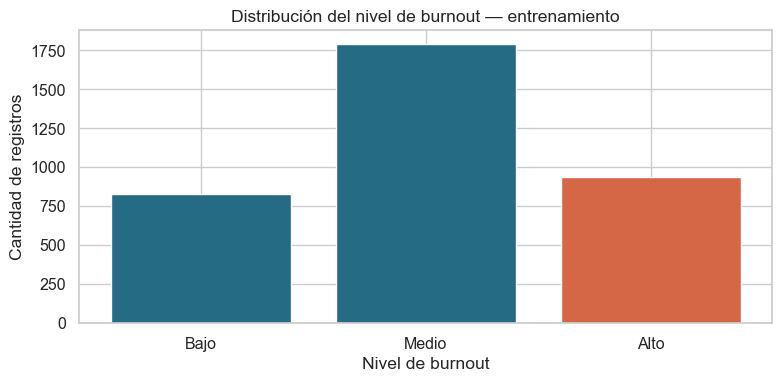

**Interpretación:** 937 de 3555 registros (26.4%) tienen burnout alto. La frecuencia de la clase positiva permite contextualizar recall, precisión y average precision; accuracy por sí sola resulta insuficiente.

In [ ]:
conteos = eda.burnout_level.value_counts().reindex(['Low','Medium','High'], fill_value=0)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(['Bajo','Medio','Alto'], conteos, color=[AZUL,AZUL,NARANJA])
ax.set(title='Distribución del nivel de burnout — entrenamiento', xlabel='Nivel de burnout', ylabel='Cantidad de registros')
plt.tight_layout(); plt.show()
display(Markdown(f'**Interpretación:** {conteos["High"]} de {len(eda)} registros ({conteos["High"]/len(eda):.1%}) tienen burnout alto. La frecuencia de la clase positiva permite contextualizar recall, precisión y average precision; accuracy por sí sola resulta insuficiente.'))

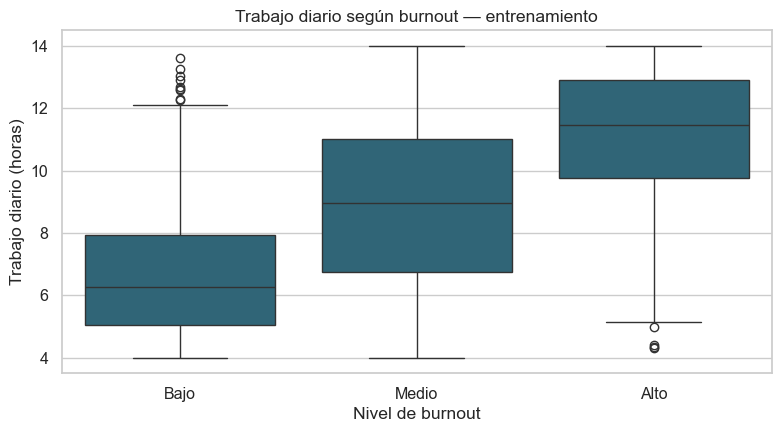

**Interpretación:** las medianas de jornada son Low: 6.25 h, Medium: 8.95 h, High: 11.47 h. La comparación muestra asociación entre jornada y etiqueta; no demuestra que reducir horas cause un cambio equivalente en burnout.

In [ ]:
fig, ax = plt.subplots(figsize=(8,4.5))
sns.boxplot(data=eda, x='burnout_level', y='daily_work_hours', order=['Low','Medium','High'], color=AZUL, ax=ax)
ax.set(title='Trabajo diario según burnout — entrenamiento', xlabel='Nivel de burnout', ylabel='Trabajo diario (horas)')
ax.set_xticks(range(3), ['Bajo','Medio','Alto'])
plt.tight_layout(); plt.show()
medianas = eda.groupby('burnout_level').daily_work_hours.median()
display(Markdown('**Interpretación:** las medianas de jornada son '+', '.join(f'{k}: {medianas[k]:.2f} h' for k in ['Low','Medium','High'])+'. La comparación muestra asociación entre jornada y etiqueta; no demuestra que reducir horas cause un cambio equivalente en burnout.'))

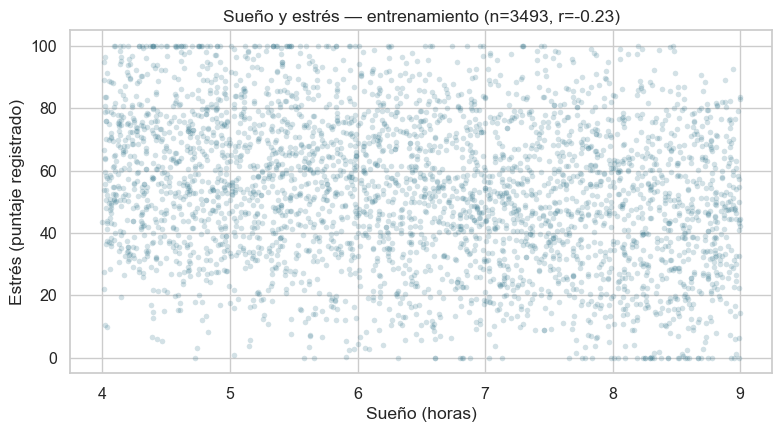

**Interpretación:** la correlación lineal entre sueño y estrés es -0.23. La dispersión permite evaluar cuánto se solapan los registros; esta relación no basta para explicar cada caso individual.

In [ ]:
d = eda.dropna(subset=['sleep_hours','stress_level'])
r = d.sleep_hours.corr(d.stress_level)
fig, ax = plt.subplots(figsize=(8,4.5))
sns.scatterplot(data=d, x='sleep_hours', y='stress_level', color=AZUL, alpha=.2, s=16, linewidth=0, ax=ax)
ax.set(title=f'Sueño y estrés — entrenamiento (n={len(d)}, r={r:.2f})', xlabel='Sueño (horas)', ylabel='Estrés (puntaje registrado)')
plt.tight_layout(); plt.show()
display(Markdown(f'**Interpretación:** la correlación lineal entre sueño y estrés es {r:.2f}. La dispersión permite evaluar cuánto se solapan los registros; esta relación no basta para explicar cada caso individual.'))

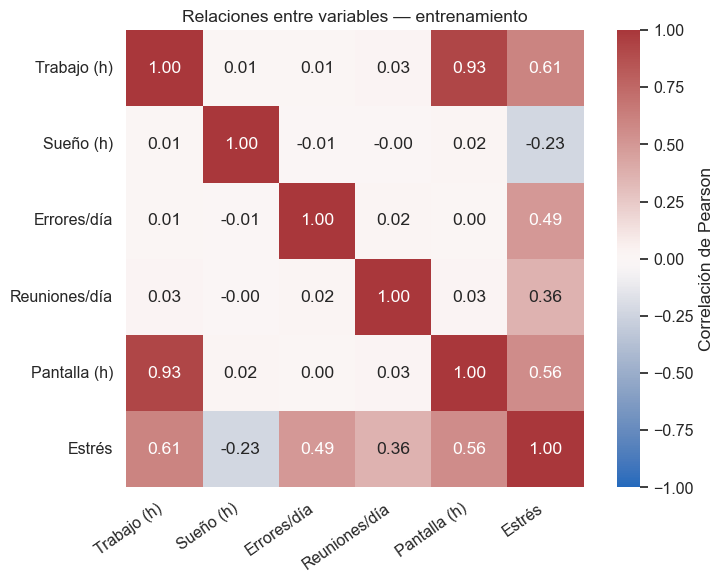

**Interpretación:** trabajo y pantalla tienen una correlación de 0.93; trabajo y estrés, de 0.61. Las correlaciones usan pares disponibles, por lo que el número de observaciones puede variar. Una asociación alta entre predictores puede aportar información redundante.

In [ ]:
variables = ['daily_work_hours','sleep_hours','bugs_per_day','meetings_per_day','screen_time','stress_level']
etiquetas = ['Trabajo (h)','Sueño (h)','Errores/día','Reuniones/día','Pantalla (h)','Estrés']
corr = eda[variables].corr()
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
    xticklabels=etiquetas, yticklabels=etiquetas, square=True, cbar_kws={'label':'Correlación de Pearson'}, ax=ax)
ax.set_title('Relaciones entre variables — entrenamiento')
plt.xticks(rotation=35, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()
display(Markdown(f'**Interpretación:** trabajo y pantalla tienen una correlación de {corr.loc["daily_work_hours","screen_time"]:.2f}; trabajo y estrés, de {corr.loc["daily_work_hours","stress_level"]:.2f}. Las correlaciones usan pares disponibles, por lo que el número de observaciones puede variar. Una asociación alta entre predictores puede aportar información redundante.'))

## 3. Preprocesamiento y feature engineering
Conservé jornada, sueño, cafeína, errores, commits, reuniones, pantalla y ejercicio como indicadores laborales y de hábitos. Descarté `burnout_level` por ser el objetivo; edad y experiencia para evitar usar atributos personales como criterio de priorización; y `stress_level` porque no conozco cómo se construyó la etiqueta y podría ser una variable demasiado cercana al resultado. Esto cambia deliberadamente el conjunto de predictores respecto de la pre-entrega 7: sus métricas no son directamente comparables.

Retomé mi función para categorizar la jornada: reducida (<8 h), completa (8 a 10 h) y excesiva (>10 h). Es una descripción de horas, no una clasificación contractual. Es redundante con las horas originales, pero permite incorporar explícitamente una transformación categórica; su aporte real requeriría una comparación posterior sin esa variable.

Utilicé mediana y escalado estándar para numéricas, y moda más One-Hot para la categoría. Cada transformación se ajusta dentro del pipeline: solo ve el entrenamiento de cada partición de validación. Las reglas fijas de jornada no aprenden estadísticas del dataset.

In [ ]:
def categorizar_jornada(horas):
    if pd.isna(horas):
        return np.nan
    elif horas > 10:
        return 'Jornada Excesiva'
    elif horas >= 8:
        return 'Jornada Completa'
    return 'Jornada Reducida'

numericas = ['daily_work_hours','sleep_hours','caffeine_intake','bugs_per_day',
             'commits_per_day','meetings_per_day','screen_time','exercise_hours']
X = datos[numericas].copy()
X['categoria_jornada'] = X.daily_work_hours.apply(categorizar_jornada)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

def preprocesador(escalar=True):
    pasos = [('imputacion', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('escalado', StandardScaler()))
    return ColumnTransformer([
        ('numericas', Pipeline(pasos), numericas),
        ('categoricas', Pipeline([
            ('imputacion', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['categoria_jornada'])])
print('Predictores finales:', X_train.columns.tolist())
print('Objetivo:', objetivo, '| Positivo: High (1)')
print('Excluidas del modelo: age, experience_years, stress_level, burnout_level')
display(X_train.head())

Predictores finales: ['daily_work_hours', 'sleep_hours', 'caffeine_intake', 'bugs_per_day', 'commits_per_day', 'meetings_per_day', 'screen_time', 'exercise_hours', 'categoria_jornada']
Objetivo: burnout_level | Positivo: High (1)
Excluidas del modelo: age, experience_years, stress_level, burnout_level


,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,categoria_jornada
1782,8.52,4.91,3.0,9.0,18.0,7.0,10.67,1.32,Jornada Completa
2792,11.59,8.73,1.0,19.0,19.0,8.0,15.36,0.63,Jornada Excesiva
1506,6.25,6.36,4.0,0.0,5.0,0.0,9.88,1.69,Jornada Reducida
2198,13.90,5.61,1.0,14.0,11.0,1.0,16.54,0.17,Jornada Excesiva
637,8.23,8.57,2.0,19.0,4.0,2.0,11.88,1.53,Jornada Completa


## 4. Modelado y evaluación
### 4.1. Comparación dentro del entrenamiento
Usé 80 % para entrenamiento y 20 % para prueba, con estratificación y semilla 42. Comparé regresión logística y Random Forest con parámetros fijos y pesos balanceados. Agregué un modelo que siempre predice la clase más frecuente como referencia mínima.

Elegí el modelo con **mayor F1 promedio en validación cruzada de 5 particiones** sobre entrenamiento. F1 equilibra precisión y recall: omitir casos altos y generar alertas falsas tienen costos distintos, aún no cuantificados. Mantengo el umbral predeterminado de 0,5; cualquier ajuste futuro debe realizarse dentro del entrenamiento, nunca en prueba.

In [ ]:
modelos = {
    'Referencia mayoritaria': Pipeline([('preparacion', preprocesador(False)), ('modelo', DummyClassifier(strategy='most_frequent'))]),
    'Regresión Logística': Pipeline([('preparacion', preprocesador()), ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA))]),
    'Random Forest': Pipeline([('preparacion', preprocesador(False)), ('modelo', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEMILLA, n_jobs=1))])}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv,
        scoring={'f1':'f1','recall':'recall','ap':'average_precision'}, n_jobs=1)
    filas.append({'Modelo': nombre, 'F1 medio': scores['test_f1'].mean(),
        'F1 desvío': scores['test_f1'].std(), 'Recall medio': scores['test_recall'].mean(),
        'AP media': scores['test_ap'].mean()})
validacion = pd.DataFrame(filas).set_index('Modelo').sort_values('F1 medio', ascending=False)
display(validacion.round(4))
nombre_elegido = validacion.index[0]
print('Modelo elegido sin consultar prueba:', nombre_elegido)

,F1 medio,F1 desvío,Recall medio,AP media
Modelo,,,,
Regresión Logística,0.7725,0.0113,0.8805,0.8793
Random Forest,0.7219,0.0257,0.6479,0.8303
Referencia mayoritaria,0.0000,0.0000,0.0000,0.2636


Modelo elegido sin consultar prueba: Regresión Logística


### 4.2. Evaluación final en prueba
Una vez elegido el modelo, ajusté las configuraciones fijas con todo el entrenamiento y reporté los resultados en la misma prueba para contextualizar la comparación. No cambio el ganador según esta tabla. Precisión indica cuántas alertas son correctas; recall, cuántos casos altos detecto; F1 combina ambos. AUC-ROC mide ordenamiento y average precision (AP) resume precisión-recall. La referencia de AP de un ranking aleatorio es aproximadamente la proporción positiva.

**ROC y AUC:** las curvas se calculan con las probabilidades estimadas de la clase positiva, **burnout alto (1)**, obtenidas con `predict_proba(X_test)[:, 1]`. No se usan las etiquetas de `predict` para construirlas. La ROC recorre distintos umbrales sobre esas probabilidades; las matrices de confusión y métricas de clasificación corresponden al umbral predeterminado de 0,5. Las probabilidades aún no fueron evaluadas como estimaciones calibradas de riesgo.


,Accuracy,Precisión,Recall,F1,AUC-ROC,AP
Modelo,,,,,,
Referencia mayoritaria,0.7368,0.0000,0.0000,0.0000,0.5000,0.2632
Regresión Logística,0.8729,0.7065,0.8846,0.7856,0.9528,0.8793
Random Forest,0.8830,0.8283,0.7009,0.7593,0.9453,0.8468


Proporción de burnout alto en prueba: 0.2632


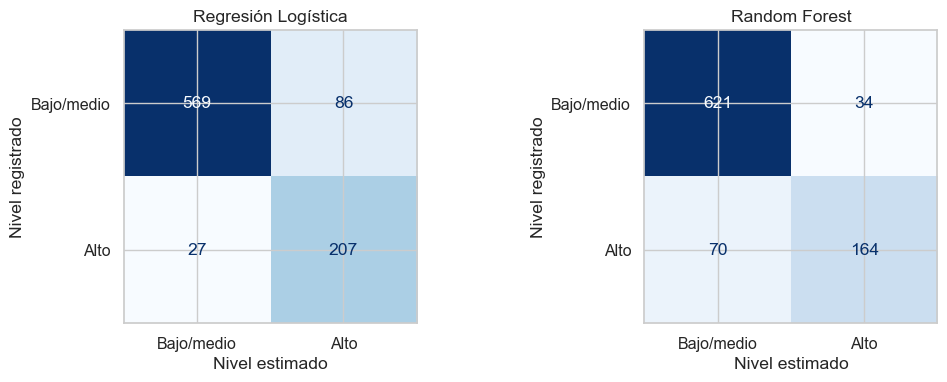

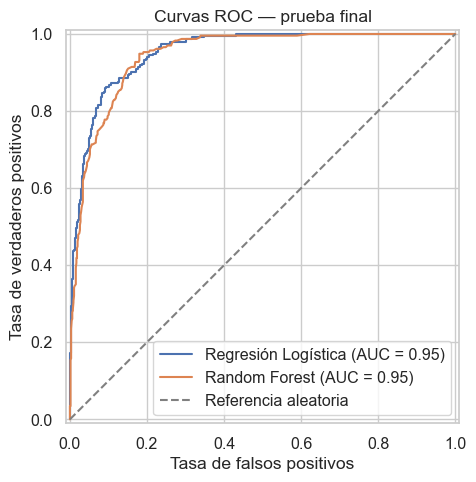

**Interpretación:** el modelo elegido (Regresión Logística) omite 27 casos altos y genera 86 alertas falsas en esta prueba. Estos errores muestran por qué una alerta necesita revisión y por qué no debe interpretarse una ausencia de alerta como garantía de bienestar.

In [ ]:
filas, predicciones, probabilidades = [], {}, {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:,1]
    predicciones[nombre], probabilidades[nombre] = pred, prob
    filas.append({'Modelo':nombre, 'Accuracy':accuracy_score(y_test,pred),
        'Precisión':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0), 'F1':f1_score(y_test,pred,zero_division=0),
        'AUC-ROC':roc_auc_score(y_test,prob), 'AP':average_precision_score(y_test,prob)})
resultados = pd.DataFrame(filas).set_index('Modelo')
display(resultados.round(4))
print(f'Proporción de burnout alto en prueba: {y_test.mean():.4f}')
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, nombre in zip(axes, ['Regresión Logística','Random Forest']):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], labels=[0,1],
        display_labels=['Bajo/medio','Alto'], cmap='Blues', colorbar=False, ax=ax)
    ax.set(title=nombre, xlabel='Nivel estimado', ylabel='Nivel registrado')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,5))
for nombre in ['Regresión Logística','Random Forest']:
    RocCurveDisplay.from_predictions(y_test, probabilidades[nombre], name=nombre, ax=ax)
ax.plot([0,1],[0,1],'--',color='gray',label='Referencia aleatoria')
ax.set(title='Curvas ROC — prueba final', xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
ax.legend(); plt.tight_layout(); plt.show()
pred = predicciones[nombre_elegido]
fn = int(((y_test==1)&(pred==0)).sum())
fp = int(((y_test==0)&(pred==1)).sum())
display(Markdown(f'**Interpretación:** el modelo elegido ({nombre_elegido}) omite {fn} casos altos y genera {fp} alertas falsas en esta prueba. Estos errores muestran por qué una alerta necesita revisión y por qué no debe interpretarse una ausencia de alerta como garantía de bienestar.'))

### 4.3. Variables que utiliza el modelo
Calculé importancia por permutación sobre entrenamiento para describir cuánto cae F1 al alterar cada predictor. Es una explicación exploratoria del modelo ajustado; puede favorecer patrones aprendidos y repartir importancia entre variables correlacionadas. No demuestra causalidad.

In [ ]:
importancias = permutation_importance(modelos[nombre_elegido], X_train, y_train,
    scoring='f1', n_repeats=5, random_state=SEMILLA, n_jobs=1)
ranking = pd.DataFrame({'Variable':X.columns, 'Caída F1':importancias.importances_mean,
                        'Desvío':importancias.importances_std}).sort_values('Caída F1', ascending=False)
display(ranking.round(4))

,Variable,Caída F1,Desvío
0,daily_work_hours,0.2209,0.0096
3,bugs_per_day,0.1888,0.0069
5,meetings_per_day,0.0933,0.0043
1,sleep_hours,0.0410,0.0031
2,caffeine_intake,0.0393,0.0062
7,exercise_hours,0.0145,0.0028
6,screen_time,-0.0034,0.0024
8,categoria_jornada,-0.0038,0.0028
4,commits_per_day,-0.0046,0.0018


## 5. Conclusiones y recomendaciones
### Resultados del proyecto

In [ ]:
fila = resultados.loc[nombre_elegido]
display(Markdown(
    f'En este trabajo pasé de {len(df):,} registros originales a {len(datos):,} registros utilizables. '
    f'La limpieza excluyó {len(df)-len(datos):,} filas; por eso las conclusiones corresponden al subconjunto que cumple los filtros. '
    f'La validación cruzada seleccionó **{nombre_elegido}**, con F1 medio de **{validacion.loc[nombre_elegido,"F1 medio"]:.3f}**. '
    f'En prueba obtuvo **F1 = {fila["F1"]:.3f}**, **recall = {fila["Recall"]:.3f}** y **precisión = {fila["Precisión"]:.3f}**. '
    f'La referencia mayoritaria obtuvo F1 = {resultados.loc["Referencia mayoritaria","F1"]:.3f}. '
    'Estas métricas describen esta partición del archivo y no aseguran el mismo desempeño en otros equipos.'))

En este trabajo pasé de 7,000 registros originales a 4,444 registros utilizables. La limpieza excluyó 2,556 filas; por eso las conclusiones corresponden al subconjunto que cumple los filtros. La validación cruzada seleccionó **Regresión Logística**, con F1 medio de **0.773**. En prueba obtuvo **F1 = 0.786**, **recall = 0.885** y **precisión = 0.706**. La referencia mayoritaria obtuvo F1 = 0.000. Estas métricas describen esta partición del archivo y no aseguran el mismo desempeño en otros equipos.

### ¿Qué aprendí y qué acción propongo?
En el entrenamiento, la mediana de jornada aumenta de 6,25 horas en burnout bajo a 11,47 horas en burnout alto. Sueño y estrés muestran una relación negativa débil (r = −0,23), mientras que trabajo y pantalla aportan información muy relacionada (r = 0,93). Estas asociaciones no prueban causalidad.

Elegí regresión logística porque tuvo el mayor F1 en validación cruzada (0,773 frente a 0,722 de Random Forest). En prueba también logró mayor F1 (0,786 frente a 0,759) y recall (0,885 frente a 0,701). Omitió 27 casos altos frente a 70 de Random Forest, a cambio de 86 alertas falsas frente a 34. Para el uso preventivo propuesto, mi recomendación **prioriza el recall para minimizar falsos negativos**, aceptando menor precisión y más revisiones. La selección estadística se realizó por F1 de validación, no por maximizar recall en prueba. Si la capacidad de seguimiento fuera limitada, ese intercambio exigiría revisar costos y umbral dentro del entrenamiento antes de decidir su uso.

Propongo comenzar con una revisión agregada y voluntaria de jornadas, reuniones y oportunidades de descanso. Si se valida el enfoque con información documentada, las señales podrían orientar conversaciones de bienestar y revisión de carga. No utilizaría los resultados para sanciones ni decisiones laborales individuales. Mediría la evolución de la carga y la percepción de bienestar antes y después de una intervención; este análisis por sí solo no estima su efecto.

### Plan de seguimiento de negocio
Este es un **plan futuro**, no una intervención realizada ni una promesa de impacto. Antes de una prueba se deben verificar la procedencia, la construcción de la etiqueta y la disponibilidad de cada predictor antes de la decisión. El archivo no permite establecer si errores o commits anteceden al desgaste.

**Responsables:** Bienestar coordinaría el seguimiento voluntario; la persona responsable del equipo revisaría la carga de trabajo y Datos supervisaría calidad y desempeño. Los resultados no se usarían para sanciones ni evaluación individual de rendimiento.

**Período propuesto:** dos semanas de línea de base y seis semanas de prueba. Los umbrales siguientes son metas iniciales a acordar, no resultados del dataset.

| Indicador | Definición y frecuencia | Criterio propuesto y acción |
|---|---|---|
| Calidad de datos | Faltantes por predictor y porcentaje de registros excluidos; semanal | Investigar aumentos de más de 5 puntos porcentuales frente a la línea de base antes de emitir nuevas señales. |
| Capacidad de revisión | Alertas / registros evaluados y revisiones completadas / alertas; semanal | Procurar revisar al menos 90 % de alertas en cinco días hábiles. Si se supera la capacidad, revisar el proceso y validar cualquier cambio de umbral dentro del entrenamiento. |
| Desempeño técnico | Recall, precisión y F1 con etiquetas independientes y documentadas; al cierre, informando muestra e incertidumbre | Meta inicial: recall >= 0,85 y precisión >= 0,65. Si no se cumple o la muestra es insuficiente, no ampliar el uso. El volumen de alertas no demuestra desempeño. |
| Carga de trabajo | Jornadas de más de 10 h / total de jornadas con datos, agregado por equipo; semanal | Meta exploratoria: reducir la proporción un 10 % relativo al cierre frente a la línea de base, informando cantidad de registros y cobertura. |
| Equidad y cobertura | Faltantes, exclusiones y errores por grupos relevantes, con datos suficientes y uso autorizado; al inicio y cierre | Investigar diferencias persistentes y contrastar filtros o variables alternativas mediante validación. Excluir edad no elimina todos los sesgos. |

Reducir jornadas largas no prueba una reducción de burnout. Para evaluar bienestar incorporaría mediciones voluntarias documentadas antes y después y un diseño de comparación adecuado. Con este archivo no puedo medir ese impacto ni atribuirlo causalmente al modelo.

### Limitaciones y próximos pasos
- **Procedencia y etiqueta:** falta documentación sobre cómo se recolectaron los datos y se definió burnout. Excluir estrés reduce una posible dependencia directa, pero no descarta que la etiqueta se haya construido con otros predictores. Debe verificarse antes de confiar en las métricas.
- **Selección:** los filtros eliminan faltantes en variables clave y pueden sesgar la población. Compararía el criterio edad-experiencia con una alternativa menos restrictiva dentro del entrenamiento.
- **Tiempo y personas:** no hay fechas ni identificadores. Si hubiera registros repetidos de una persona, la separación aleatoria podría sobreestimar el desempeño; haría una separación por persona o temporal.
- **Generalización:** falta validación externa, evaluación por grupos y un análisis de estabilidad con otras particiones. El desvío de F1 entre folds no es un intervalo de confianza.
- **Decisiones de negocio:** faltan costos de errores, capacidad de seguimiento y evaluación de calibración. Ajustaría el umbral con validación y una nueva prueba independiente.
- **Ingeniería de variables:** compararía el modelo con y sin categoría de jornada para medir si aporta información adicional.

### Continuidad con las entregas anteriores
Conservé el dataset, los filtros explícitos, la función de jornada, el estilo visual y los dos modelos de la [pre-entrega 7](https://github.com/DaianaSep/pre-entrega-7/blob/main/Sepulveda_Daiana_PreEntrega_M9.ipynb). Integré el [EDA visual](https://github.com/DaianaSep/pre-entrega-4/blob/main/EDA_Visual_Sepulveda_Daiana.ipynb) y la preparación de las primeras entregas en un único recorrido. En esta versión reservé prueba antes del EDA, agregué codificación categórica, una referencia mayoritaria y selección por validación cruzada, y descarté estrés, edad y experiencia del modelo.